# II (suite). Proches en métro, proches en revenus ? Le niveau de vie le long des lignes

La partie I a montré que le niveau de vie baisse avec le temps de trajet vers Châtelet, mais que ce temps n'explique qu'une petite part des écarts de revenus (R² de 8,5 %). Nous changeons donc de point de vue : au lieu de comparer chaque quartier au centre, nous comparons entre eux les quartiers **d'une même ligne**, qui ne sont qu'à quelques minutes les uns des autres. **Des habitants proches dans le réseau ont-ils des niveaux de vie proches ?**

Pour suivre les contrastes de revenus station par station, et pas seulement commune par commune, nous utilisons le niveau de vie de Filosofi, mesuré sur des carreaux de 200 m.

- **II.2 Les montagnes** : le niveau de vie le long du RER B et des lignes de métro 13 et 1 ;
- **II.3 L'hétérogénéité des lignes** : toutes les lignes de métro et de RER comparées, pour savoir si les écarts de revenus tiennent à la limite de Paris.

En annexe : le détail de la méthode, les autres lignes, la carte des communes plus riches que Paris et le relief du niveau de vie à Paris.

In [1]:
import matplotlib.pyplot as plt

from analyse_donnees import (
    ajouter_communes_stations,
    calculer_carreaux_traverses,
    calculer_profils_zones,
    calculer_nv_par_commune,
    calculer_nv_par_station,
    calculer_temps_trajet,
    classer_carreaux_zones,
    construire_grille_nv,
    joindre_carreaux_stations,
    mesurer_heterogeneite_lignes,
    positionner_stations_ligne,
)
from pretraitement_donnees import (
    URL_ZIP_FILOSOFI,
    URL_ZIP_IDFM,
    charger_arrets,
    charger_communes,
    charger_filosofi,
    charger_horaires,
    charger_parcours,
    charger_routes,
    charger_stations,
    charger_trips,
    construire_aretes,
    construire_centres_carreaux,
    construire_graphe_reseau,
    construire_lignes_idfm,
    construire_stations,
    indicateurs_filosofi,
    telecharger_zip,
)
from visualisation_donnees import (
    ajouter_selecteur_lignes,
    enregistrer_graphique,
    generer_carte_communes_riches,
    generer_halteres_paris_banlieue,
    generer_montagnes_par_ligne,
    generer_relief_3d,
)

## Préparation des données

- **Niveau de vie** : carreaux de 200 m de Filosofi (Insee, 2021), avec pour chacun le nombre d'habitants et la somme de leurs niveaux de vie.
- **Réseau** : lignes de métro et de RER d'Île-de-France Mobilités, avec leurs tracés, leurs stations et les temps de parcours entre stations.
- **Rattachement** : chaque carreau est rattaché à sa station la plus proche, à moins de 1,5 km.
- **Moyennes** : par station, par commune (par arrondissement à Paris) et pour l'Île-de-France, toujours pondérées par la population.

Les données (environ 3,4 Go une fois décompressées) ne sont téléchargées qu'une fois : décommenter les deux lignes ci-dessous au premier lancement.

In [2]:
# telecharger_zip(URL_ZIP_IDFM, "idfm")
# telecharger_zip(URL_ZIP_FILOSOFI, "filosofi")

In [3]:
df_filosofi = charger_filosofi("data/filosofi/france_metro/carreaux_200m_met.shp")
df_filosofi = indicateurs_filosofi(df_filosofi)
gpd_centres = construire_centres_carreaux(df_filosofi)

In [4]:
# Métro et RER seulement (charger_routes ajoute sinon le tram et le Transilien)
df_routes = charger_routes("data/idfm", modes=("metro", "rer"))
df_trips = charger_trips("data/idfm", df_routes)
gpd_idfm = construire_lignes_idfm(charger_parcours("data/idfm", df_trips))

df_arrets = charger_arrets("data/idfm", df_trips)
df_stations = charger_stations("data/idfm", df_arrets)
gpd_stations = construire_stations(df_stations)

In [5]:
df_horaires = charger_horaires("data/idfm", df_trips)
graphe_reseau = construire_graphe_reseau(construire_aretes(df_horaires))
destinations = gpd_stations.loc[
    gpd_stations["stop_name"].isin(["Châtelet - Les Halles", "Châtelet", "La Défense"]),
    "stop_id",
]
df_temps = calculer_temps_trajet(graphe_reseau, destinations)

gpd_carreaux = joindre_carreaux_stations(
    gpd_centres, gpd_stations, df_temps, distance_max=1500, vitesse_marche=75
)

In [6]:
df_nv = calculer_nv_par_station(gpd_carreaux)
nv_moyen = gpd_carreaux["ind_snv"].sum() / gpd_carreaux["ind"].sum()
gpd_communes = charger_communes()
nv_communes = calculer_nv_par_commune(gpd_centres, gpd_communes)
print(f"Niveau de vie moyen en Île-de-France : {nv_moyen:,.0f} € par an".replace(",", " "))

Niveau de vie moyen en Île-de-France : 28 543 € par an


In [7]:
def preparer_lignes(noms):
    "Stations, couleur et carreaux traversés de chaque ligne"
    lignes = {}
    for nom in noms:
        gpd_ligne = positionner_stations_ligne(gpd_stations, df_stations, gpd_idfm, nom)
        gpd_ligne = ajouter_communes_stations(gpd_ligne, gpd_communes)
        df_carreaux = calculer_carreaux_traverses(df_filosofi, gpd_ligne, gpd_idfm, nom)
        filtre = df_routes["route_short_name"] == nom
        couleur = "#" + df_routes.loc[filtre, "route_color"].iloc[0]
        lignes[nom] = (gpd_ligne, couleur, df_carreaux)
    return lignes

### II.2 Les montagnes : le niveau de vie station par station

Une « montagne » suit une ligne d'un terminus à l'autre : plus elle monte, plus les habitants autour sont aisés.

- **Barres** : les carreaux de 200 m **traversés par la ligne**, en vert au-dessus de la moyenne de l'Île-de-France, en rouge en dessous. Les trous sont des endroits sans habitants (Seine, parcs, bois).
- **Courbe** : niveau de vie autour de chaque station. **Traits bleus** : moyenne de la commune ou de l'arrondissement. **Traits noirs** : limite de Paris.
- **Panneau du bas** : habitants rattachés à chaque station. Ils sont peu nombreux dans Paris, où les stations sont proches, et beaucoup plus nombreux en banlieue.

Les échelles sont les mêmes pour toutes les lignes d'une même série (RER, puis métro), y compris celles de l'annexe : les figures sont directement comparables.

#### RER B

Dans le rapport, la part d'ouvriers opposait le long du RER B un nord populaire, un centre parisien où ils sont rares et un sud plus aisé. Le niveau de vie montre-t-il le même contraste social ?

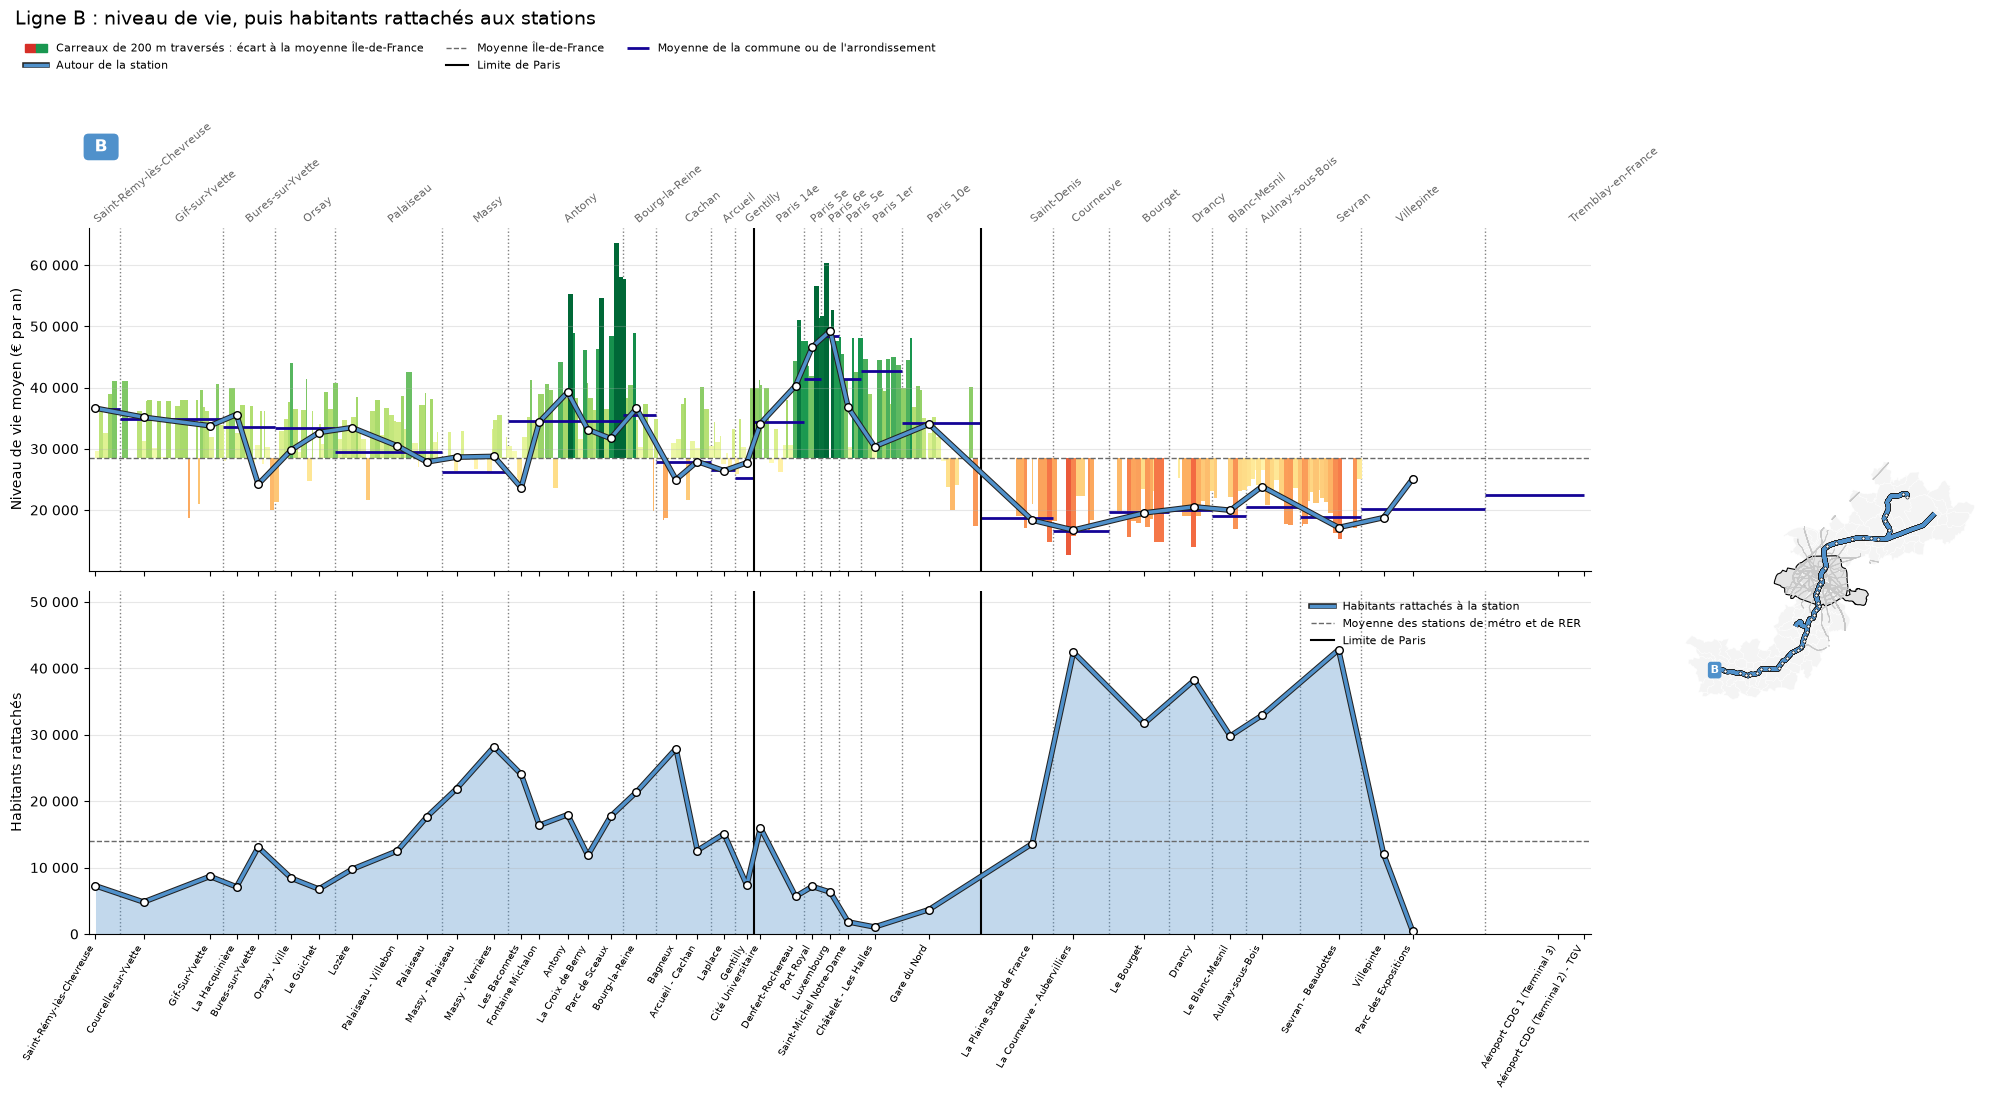

In [8]:
lignes_rer = preparer_lignes(["B", "A"])
# Même échelle pour les deux RER : le B est montré ici, le A en annexe
figures_rer = generer_montagnes_par_ligne(
    lignes_rer, df_nv, nv_moyen, nv_communes, gpd_idfm, gpd_communes
)
for nom, (ax_nv, _) in figures_rer.items():
    enregistrer_graphique(ax_nv, f"Ligne {nom} : niveau de vie et habitants")
    if nom != "B":
        plt.close(ax_nv.figure)
plt.show()

> **Lecture :** sur le RER B, entre Gare du Nord (10e arrondissement) et La Courneuve – Aubervilliers, le niveau de vie moyen autour de la station est divisé par deux : de 34 000 € à 16 700 € par an. Avec 42 400 habitants rattachés, La Courneuve – Aubervilliers en compte trois fois plus que la moyenne des stations de métro et de RER (14 000).
>
> *Champ : habitants des carreaux à moins de 1,5 km d'une station de métro ou de RER, rattachés à leur station la plus proche.* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

#### Métro : lignes 13 et 1

Deux lignes opposées : la 13, la ligne de métro où les écarts de revenus sont les plus forts (voir II.3), et la 1, qui sort de Paris vers l'ouest. Les lignes 2, 9, 11 et 14 sont en annexe.

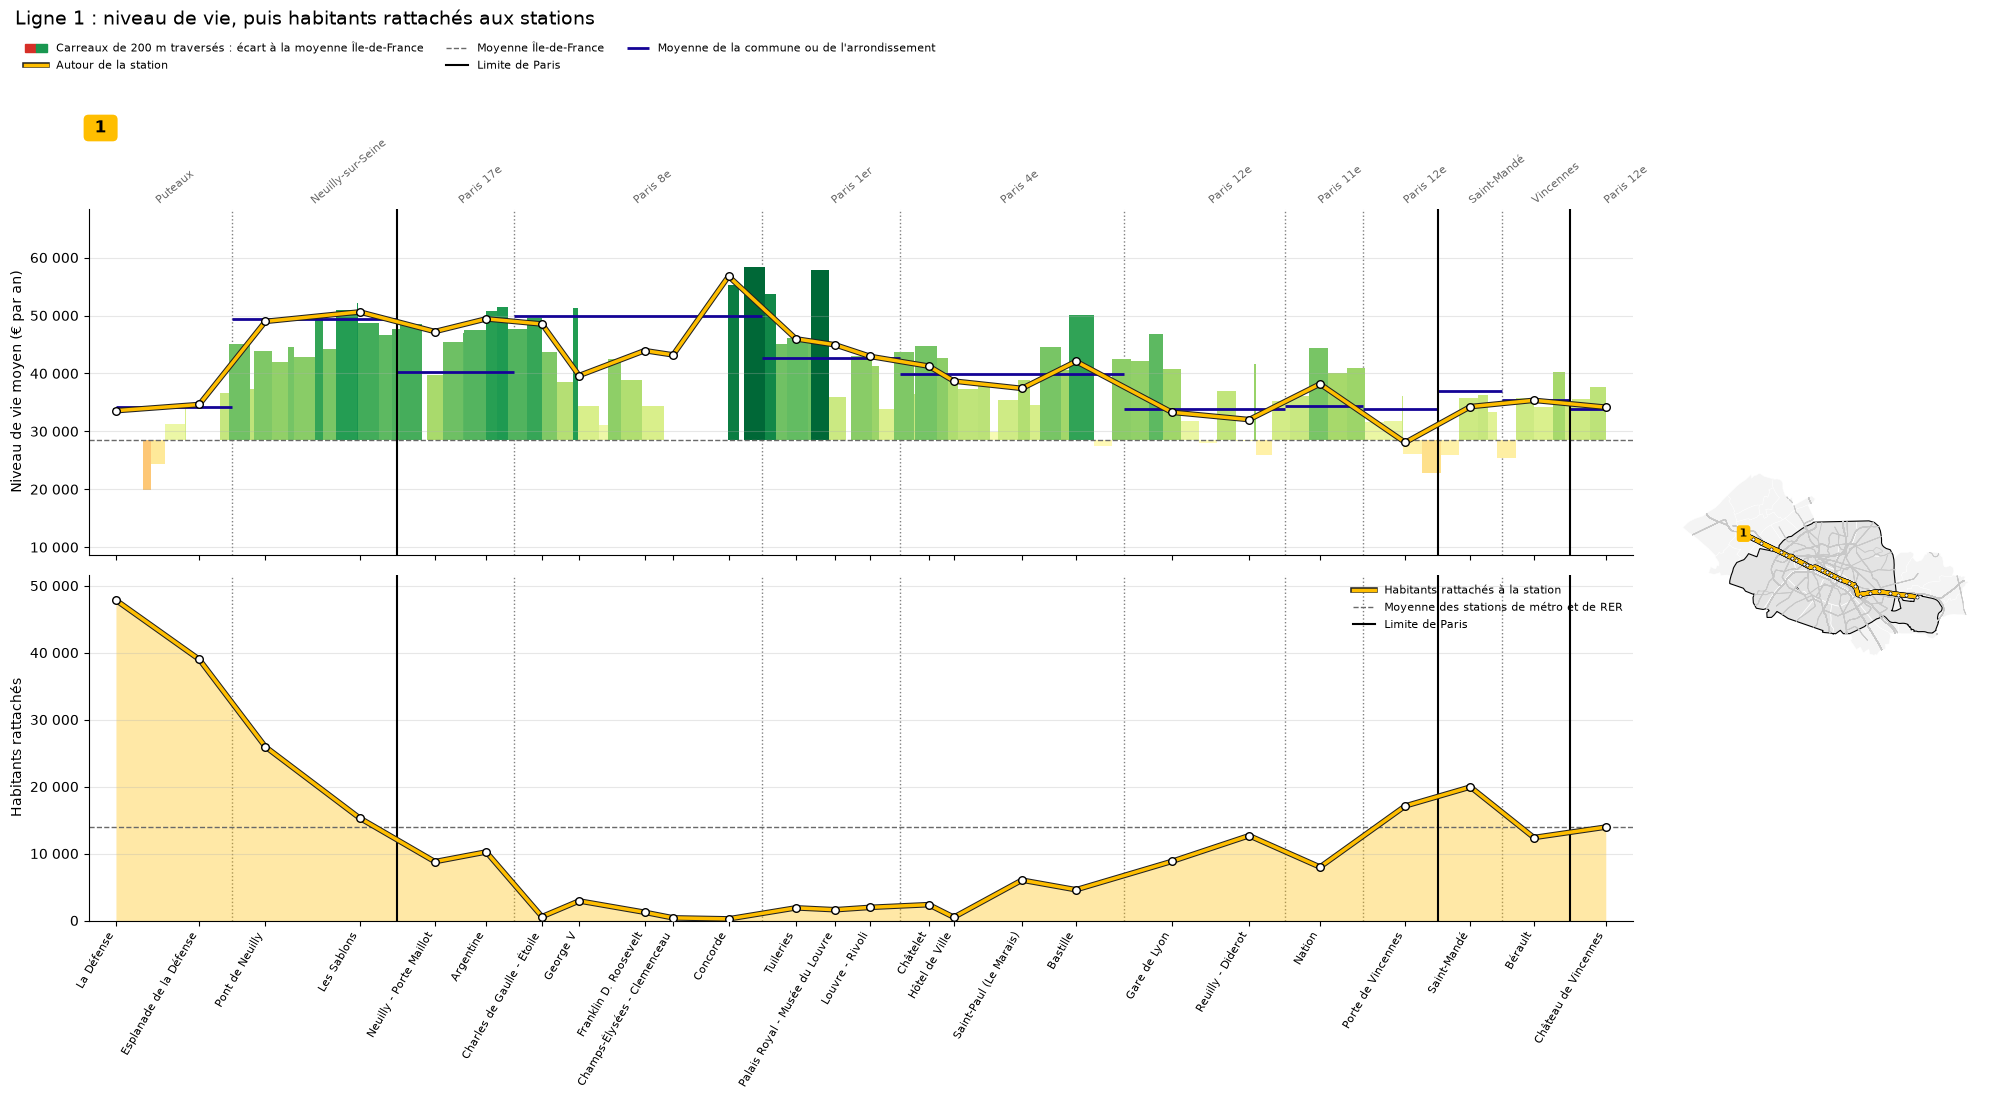

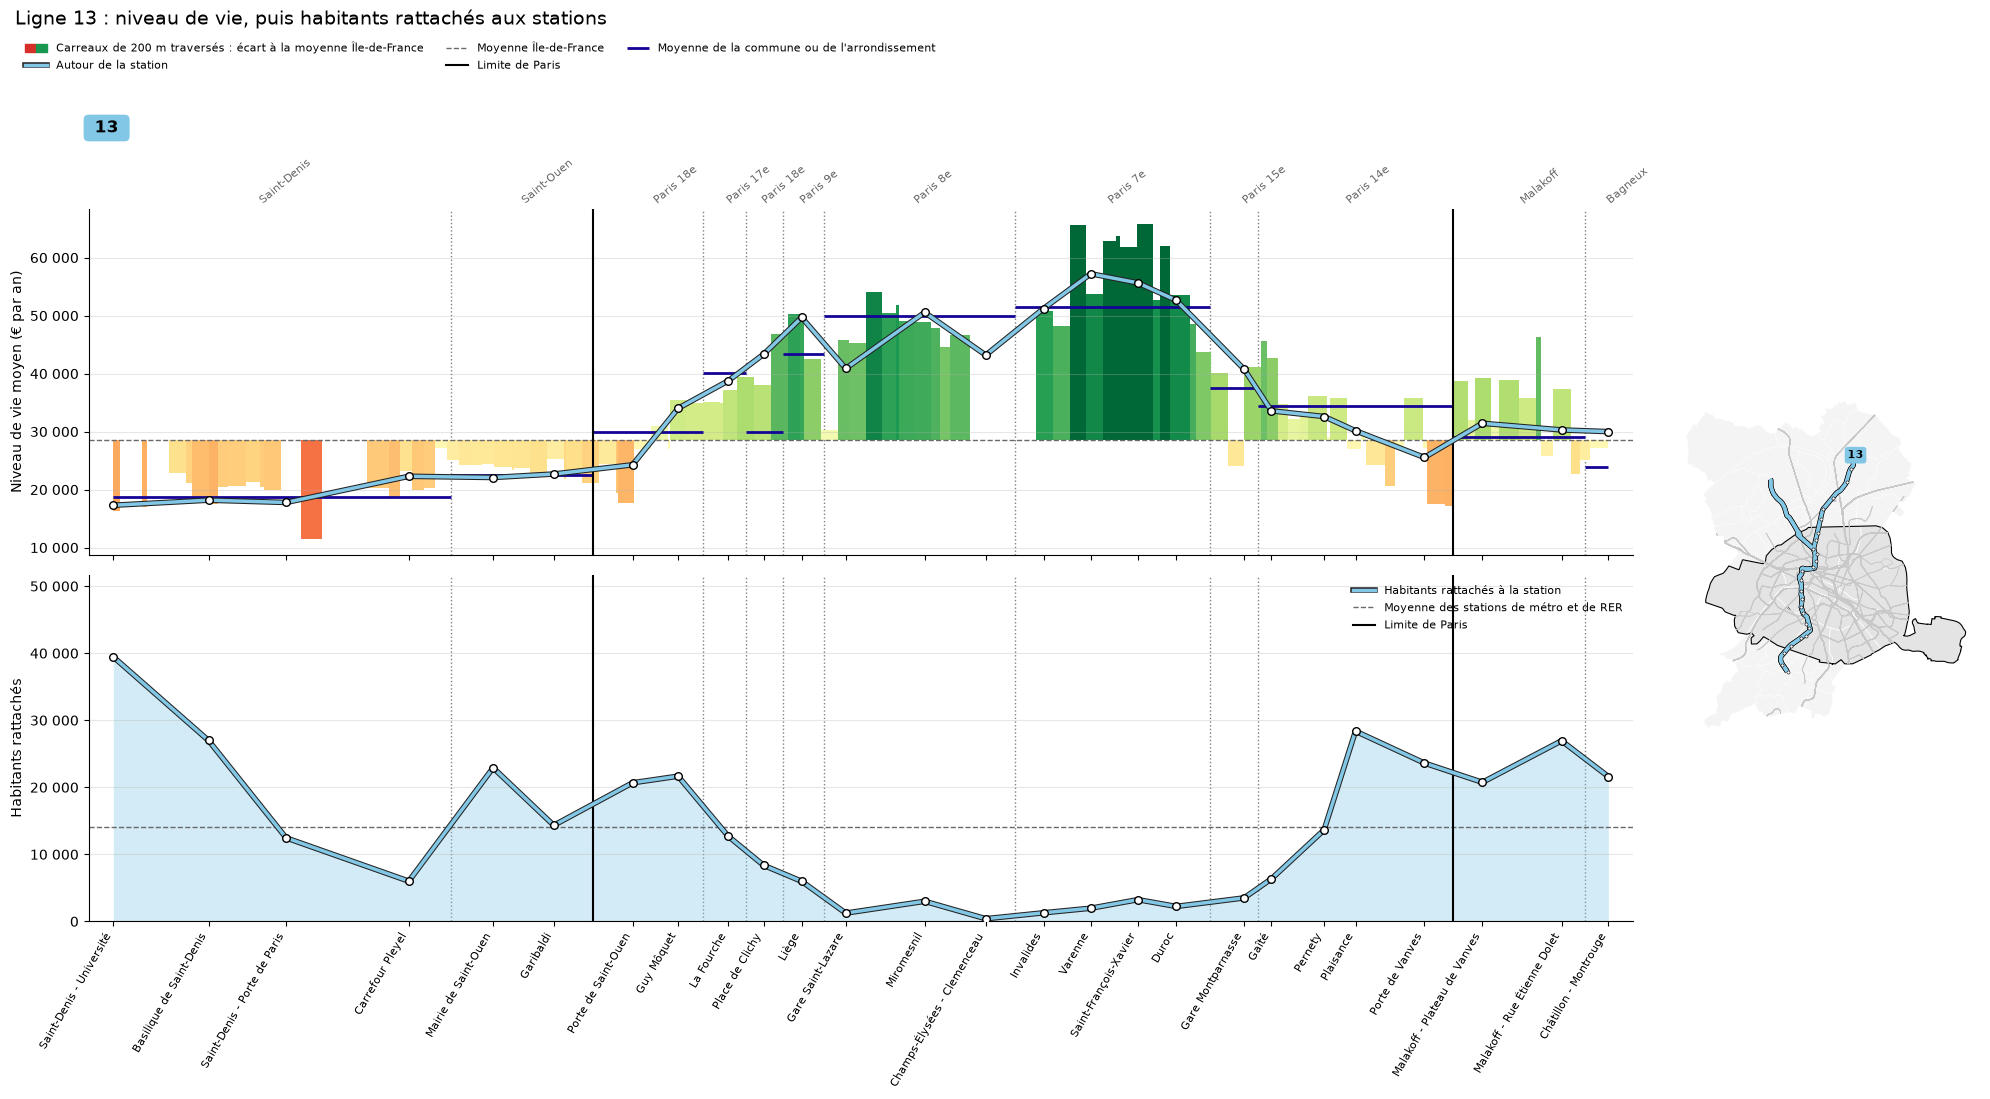

In [9]:
lignes_metro = preparer_lignes(["1", "2", "9", "11", "13", "14"])
# Même échelle pour les six lignes : la 1 et la 13 sont montrées ici, les autres en annexe
figures_metro = generer_montagnes_par_ligne(
    lignes_metro, df_nv, nv_moyen, nv_communes, gpd_idfm, gpd_communes
)
for nom, (ax_nv, _) in figures_metro.items():
    enregistrer_graphique(ax_nv, f"Ligne {nom} : niveau de vie et habitants")
    if nom not in ["1", "13"]:
        plt.close(ax_nv.figure)
plt.show()

> **Lecture :** sur la ligne 13, les 39 400 habitants rattachés à la station Saint-Denis – Université ont un niveau de vie moyen de 17 300 € par an, en dessous de la moyenne de l'Île-de-France (28 500 €). 12 km plus loin, autour de Varenne (7e arrondissement), il atteint 57 200 €, soit plus de trois fois plus, mais pour moins de 2 000 habitants.
>
> Sur la ligne 1, au contraire, sortir de Paris par l'ouest ne fait pas descendre la "montagne" : autour des Sablons (Neuilly-sur-Seine), le niveau de vie moyen est de 50 600 €, plus que dans toutes les stations parisiennes de la ligne sauf Concorde (qui n'a cependant que 300 habitants dans ses carreaux associés).
>
> *Champ : habitants des carreaux à moins de 1,5 km d'une station de métro ou de RER, rattachés à leur station la plus proche.* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

### II.3 Hétérogénéité des lignes : effet Paris et banlieues riches

Les montagnes montrent de forts écarts de revenus le long de certaines lignes. Pour comparer toutes les lignes, nous posons trois questions :

1. **Quelles lignes relient les quartiers les plus différents ?**
2. **Est-ce seulement un effet de la limite de Paris ?** Le niveau de vie fait souvent une marche au périphérique.
3. **Les banlieues riches cassent-elles l'opposition « Paris riche, banlieue pauvre » ?**

**Méthode.** Les 16 lignes de métro et les 5 RER, limités à Paris et à la petite couronne, sont découpés en tronçons de 500 m, avec les habitants à moins de 400 m du tracé. 500 m soit environ une minute de métro (1,8 min par km en petite couronne d'après la partie I). Les indicateurs portent sur le log du niveau de vie, donc les écarts de niveau de vie se lisent en % :

- **volatilité** : écart-type des variations d'un tronçon au suivant, soit l'écart de niveau de vie typique pour une minute de trajet ;
- **dispersion** : écart-type du niveau de vie sur toute la ligne, pondéré par la population ;
- **effet Paris** : part de la variance expliquée par le seul fait d'être dans Paris ou en banlieue ;
- **banlieue riche** : part des habitants de banlieue de la ligne qui vivent dans une commune plus riche que Paris.

Le détail des choix est en annexe A.1.

In [10]:
gpd_zones, nv_paris = classer_carreaux_zones(gpd_centres, gpd_communes)
df_profils_zones = calculer_profils_zones(
    gpd_idfm, gpd_zones, distance_max=400, longueur_troncon=500
)
df_heterogeneite = mesurer_heterogeneite_lignes(df_profils_zones)
print(f"Niveau de vie moyen à Paris : {nv_paris:,.0f} € par an".replace(",", " "))

# Tableau trié par dispersion, en % et en euros ; « — » : ligne entièrement dans Paris
pourcent = lambda v: "—" if v != v else f"{v:.0%}"
euros = lambda v: "—" if v != v else f"{v:,.0f} €".replace(",", " ")
df_heterogeneite.drop(columns=["couleur", "mode"]).transform(
    {
        "troncons": str, "volatilite": pourcent, "dispersion": pourcent,
        "effet_paris": pourcent, "nv_paris": euros, "nv_banlieue": euros,
        "part_banlieue_riche": pourcent,
    }
).rename(columns={
    "troncons": "Tronçons", "volatilite": "Volatilité", "dispersion": "Dispersion",
    "effet_paris": "Effet Paris", "nv_paris": "Niveau de vie Paris",
    "nv_banlieue": "Niveau de vie banlieue", "part_banlieue_riche": "Banlieue riche",
}).rename_axis("Ligne")

Niveau de vie moyen à Paris : 35 763 € par an


,Tronçons,Volatilité,Dispersion,Effet Paris,Niveau de vie Paris,Niveau de vie banlieue,Banlieue riche
Ligne,,,,,,,
C,69,15%,35%,60%,41 478 €,22 258 €,0%
B,75,15%,34%,40%,37 243 €,24 918 €,2%
E,69,14%,32%,8%,36 518 €,30 350 €,17%
13,36,15%,31%,43%,37 133 €,23 657 €,0%
7,43,11%,30%,47%,33 896 €,21 316 €,0%
D,58,14%,29%,44%,34 815 €,23 780 €,0%
12,35,13%,27%,18%,38 006 €,28 364 €,45%
14,50,14%,26%,47%,36 427 €,24 362 €,0%
A,66,16%,26%,20%,39 499 €,32 076 €,21%


> **Lecture :** le long de la ligne 13, le niveau de vie s'écarte de sa moyenne d'environ 31 % en général (dispersion) et varie d'environ 15 % d'un tronçon de 500 m au suivant (volatilité). 43 % de ces écarts de revenus s'expliquent par le seul fait d'être dans Paris ou en banlieue (effet Paris). Aucune de ses banlieux est plus riche que Paris.
>
> *Champ : habitants à moins de 400 m du tracé, à Paris et en petite couronne ; tronçons d'au moins 100 habitants.* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

#### Dans Paris et en banlieue, ligne par ligne

Point plein : niveau de vie moyen le long de la ligne dans Paris ; point creux : en banlieue. Plus le trait est long, plus la sortie de Paris change le niveau de vie. À droite, l'effet Paris et la part des habitants de banlieue de la ligne qui vivent dans une commune plus riche que Paris.

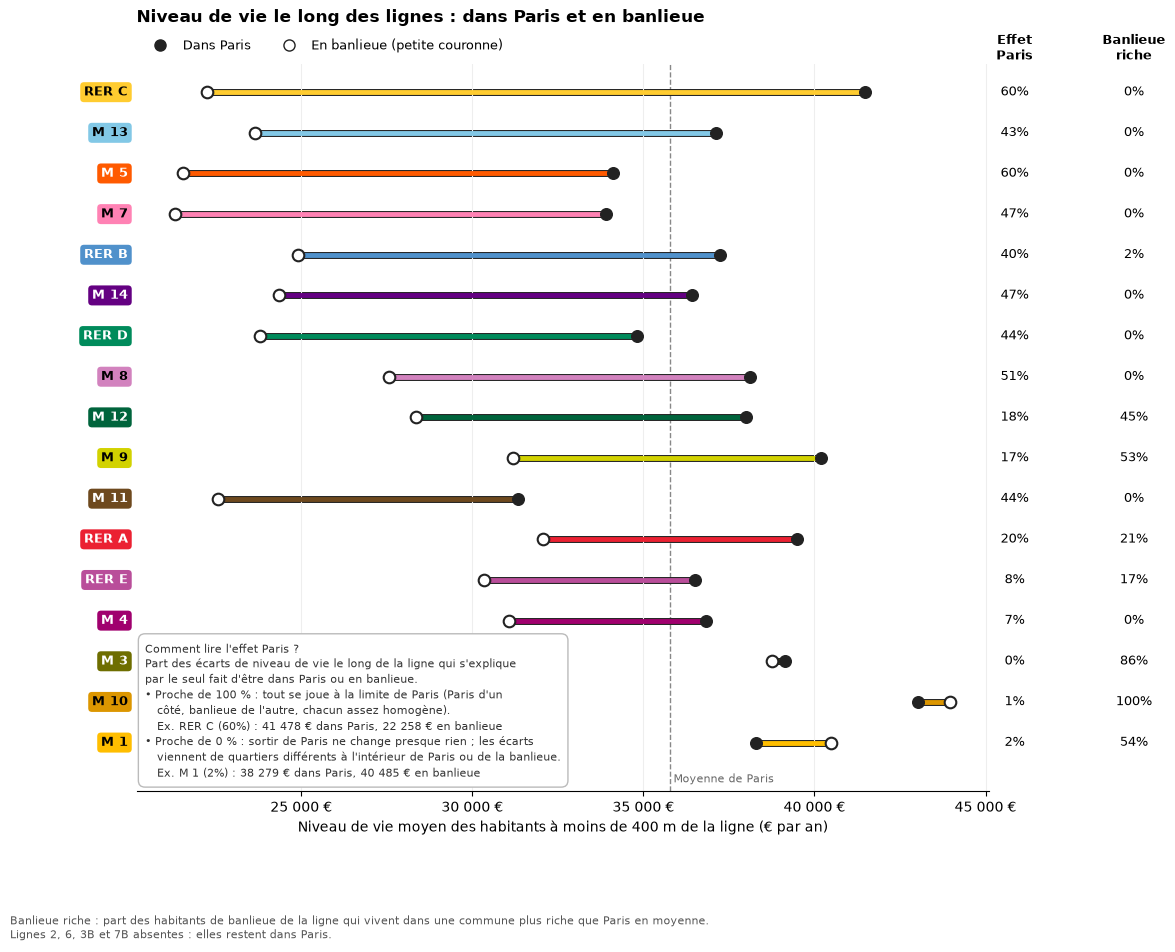

In [11]:
ax = generer_halteres_paris_banlieue(df_heterogeneite, nv_paris)
enregistrer_graphique(ax, "Hétérogénéité : Paris et banlieue par ligne")
plt.show()

> **Lecture :** le long de la ligne 13, les habitants des tronçons situés dans Paris ont un niveau de vie moyen de 37 100 € par an, contre 23 700 € pour ceux des tronçons de banlieue, soit 36 % de moins. Sur la ligne 1, c'est l'inverse : la banlieue (40 500 €) est plus riche que Paris (38 300 €), et 54 % de ses habitants de banlieue vivent dans une commune plus riche que Paris, comme Neuilly-sur-Seine.
>
> *Champ : habitants à moins de 400 m du tracé, à Paris et en petite couronne ; lignes 2, 6, 3B et 7B exclues (entièrement dans Paris).* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

**Commentaire**

- **Les lignes où les écarts de revenus sont les plus forts** sont les RER C, B et E, puis la ligne 13, la 7 et le RER D (dispersion de 29 à 35 %). Les plus homogènes en revenus sont la 10 et la 1 (11 et 17 %).
- **La limite de Paris explique une grande partie des écarts de revenus, mais pas tout** : de 40 à 60 % de la variance sur les lignes C, 5, 8, 7, 14, 11, D, 13 et B. Sur le RER E (8 %), la 9 (17 %), la 12 (18 %) et le RER A (20 %), les écarts de revenus viennent surtout de l'intérieur de Paris ou de la banlieue.
- **Vers l'ouest, la banlieue n'est pas plus pauvre que Paris.** Sur les lignes 1, 3 et 10, l'effet Paris est presque nul (0 à 2 %), et 54 à 100 % de leurs habitants de banlieue vivent dans une commune plus riche que Paris, comme Neuilly-sur-Seine (carte en annexe A.3). À l'inverse, aucun habitant de banlieue des lignes 4, 5, 7, 8, 11, 13, 14 et des RER C et D ne vit dans une commune plus riche que Paris.

### Conclusion de la partie II

**Être proches en métro ne veut pas dire être proches en revenus.** Sur la ligne 13 comme sur le RER B, quelques stations suffisent pour que le niveau de vie soit divisé par deux, voire par trois. Ces écarts de revenus ne suivent pas un simple gradient du centre vers la périphérie : ils opposent l'ouest et le sud-ouest, aisés des deux côtés du périphérique, au nord et à l'est, plus modestes. La limite de Paris en explique souvent près de la moitié, mais elle s'efface vers l'ouest, où la banlieue est aussi riche que Paris, voire plus.

C'est pourquoi le temps de trajet vers Châtelet ne rend compte que d'une petite part des inégalités (partie I) : la direction dans laquelle on s'éloigne du centre compte autant que la distance parcourue.


Pour aller plus loin sur l'explication de cette distribution : 
Stephan Heblich, Alex Trew et Yanos Zylberberg, « East-Side Story: Historical Pollution and Persistent Neighborhood Sorting » (publié dans le Journal of Political Economy, 2021 ; [version de travail accessible via le Centre for Economic Performance de la LSE](https://cep.lse.ac.uk/pubs/download/sercdp0208.pdf)

### Limites

- **Centre de Paris** : les stations sont si proches que chacune ne récupère que quelques carreaux (248 habitants pour Concorde, contre 48 000 pour La Défense). Les valeurs par station y sont fragiles ; les barres des carreaux le sont moins.
- **Lignes à branches** (13, RER A et B) : la montagne ne suit que la branche la plus longue.
- **Une seule station par habitant** : chacun est rattaché à sa station la plus proche, métro compris. Les gares du RER dans Paris (Auber, Châtelet - Les Halles…) ont donc très peu d'habitants rattachés.
- **Carreaux sans habitants** (Seine, parcs, aéroport CDG) : ils n'apparaissent pas ; ce sont les trous des montagnes.

## Annexes

### A.1 Méthode de mesure de l'hétérogénéité

- **Lignes** : les 16 métros et les 5 RER, limités à Paris et à la petite couronne (Hauts-de-Seine, Seine-Saint-Denis, Val-de-Marne). Sans cette limite, les RER (50 à 80 km) dépendraient surtout de la grande couronne et ne seraient pas comparables aux métros.
- **Tronçons de 500 m** le long du tracé (le plus long de chaque ligne), avec les habitants à moins de 400 m. Toutes les lignes sont mesurées avec la même règle, quel que soit l'espacement des stations : on mesure le territoire *traversé*, pas seulement celui desservi par chaque station. Les tronçons de moins de 100 habitants sont écartés.
- **Zone** : un tronçon est « Paris » si la majorité de ses habitants vit dans Paris, « banlieue » sinon.
- **Volatilité** : écart-type des variations du log du niveau de vie d'un tronçon au suivant, comme la volatilité d'un cours de bourse, avec « par 500 m » au lieu de « par jour ».
- **Effet Paris** : variance entre les deux zones divisée par la variance totale. 60 % veut dire que 60 % des écarts de niveau de vie le long de la ligne s'expliquent par la limite de Paris ; le reste vient des écarts à l'intérieur de Paris et à l'intérieur de la banlieue.
- **Banlieue riche** : commune de petite couronne dont le niveau de vie moyen dépasse celui de Paris.

### A.2 Autres montagnes : RER A et lignes de métro 2, 9, 11 et 14

Mêmes figures et mêmes échelles qu'en II.2. Le RER A est l'autre grande traversée de la région, d'ouest en est ; la 14 est le dernier exemple de la partie II du rapport.

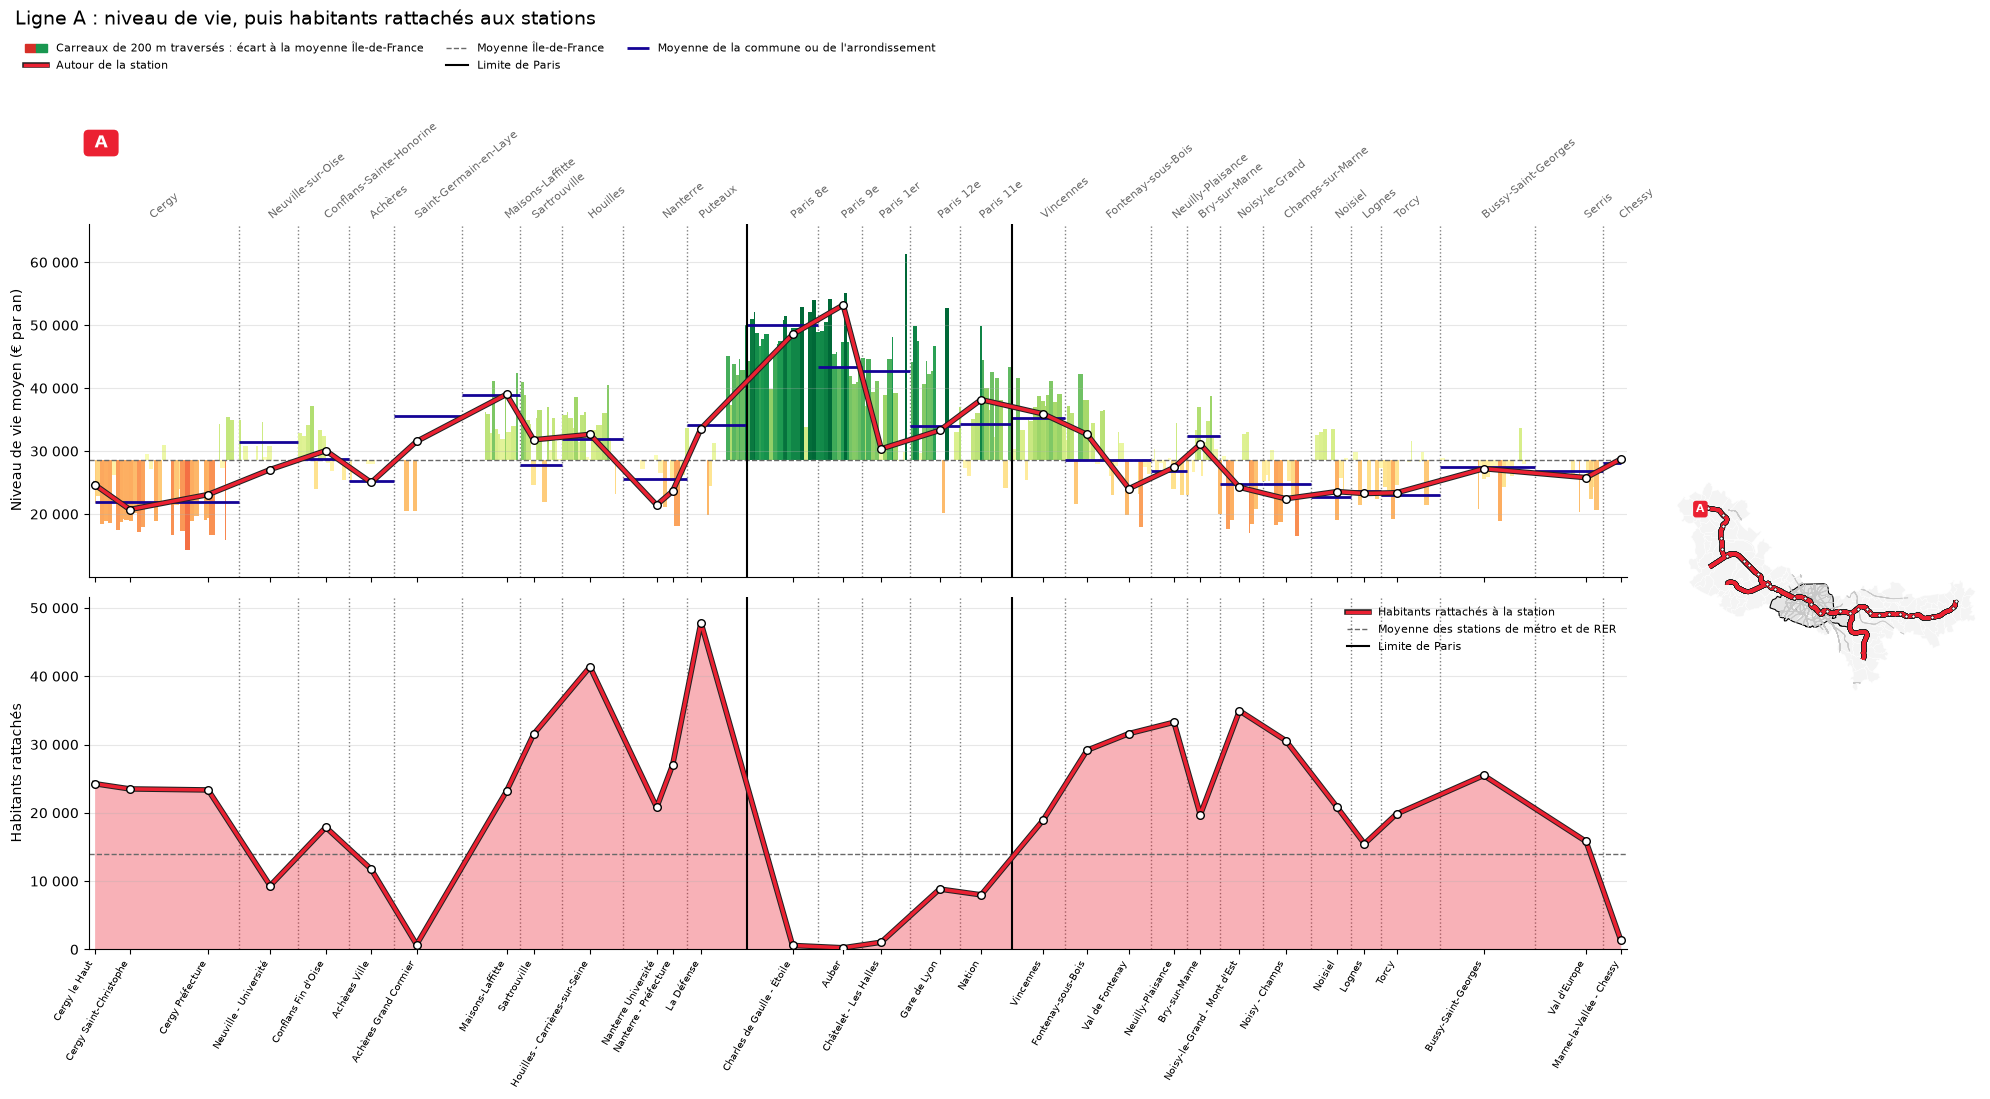

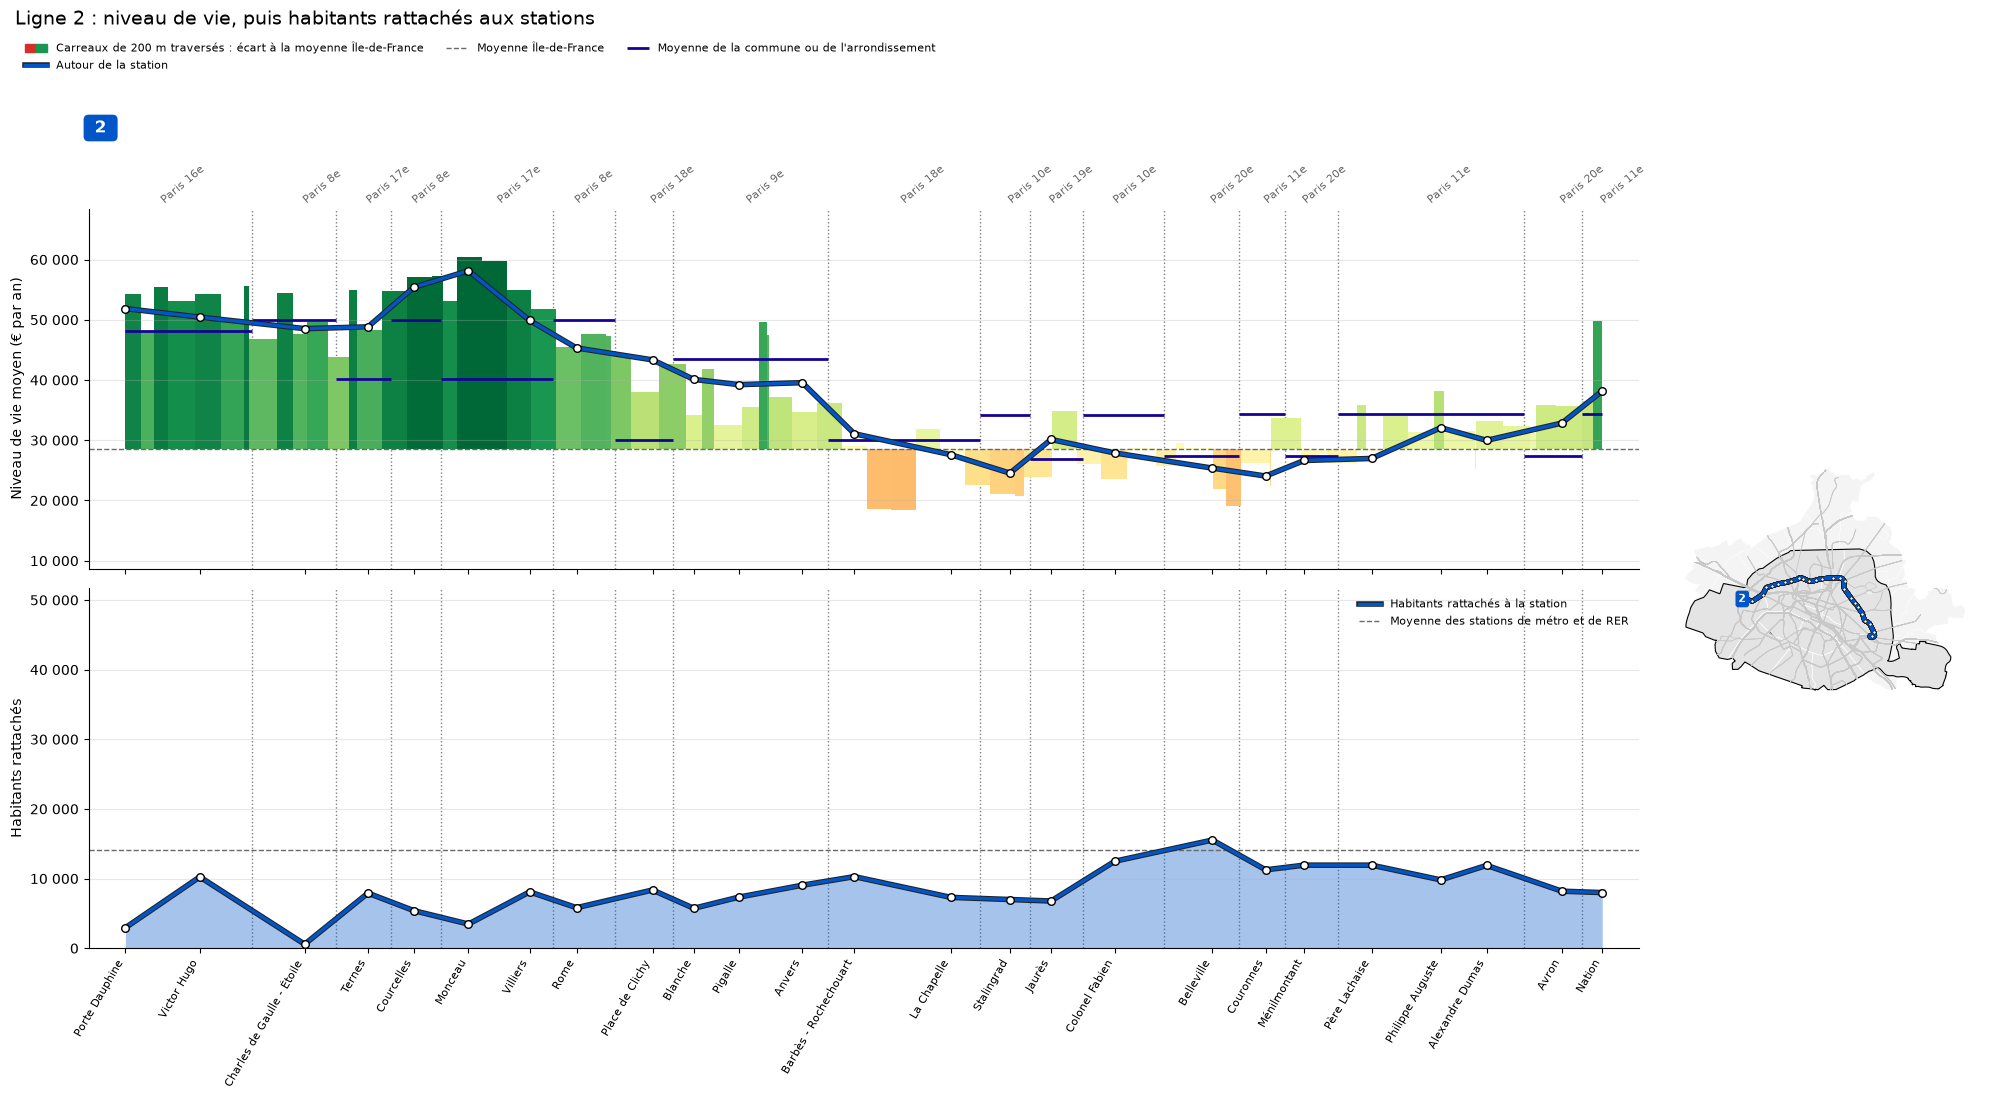

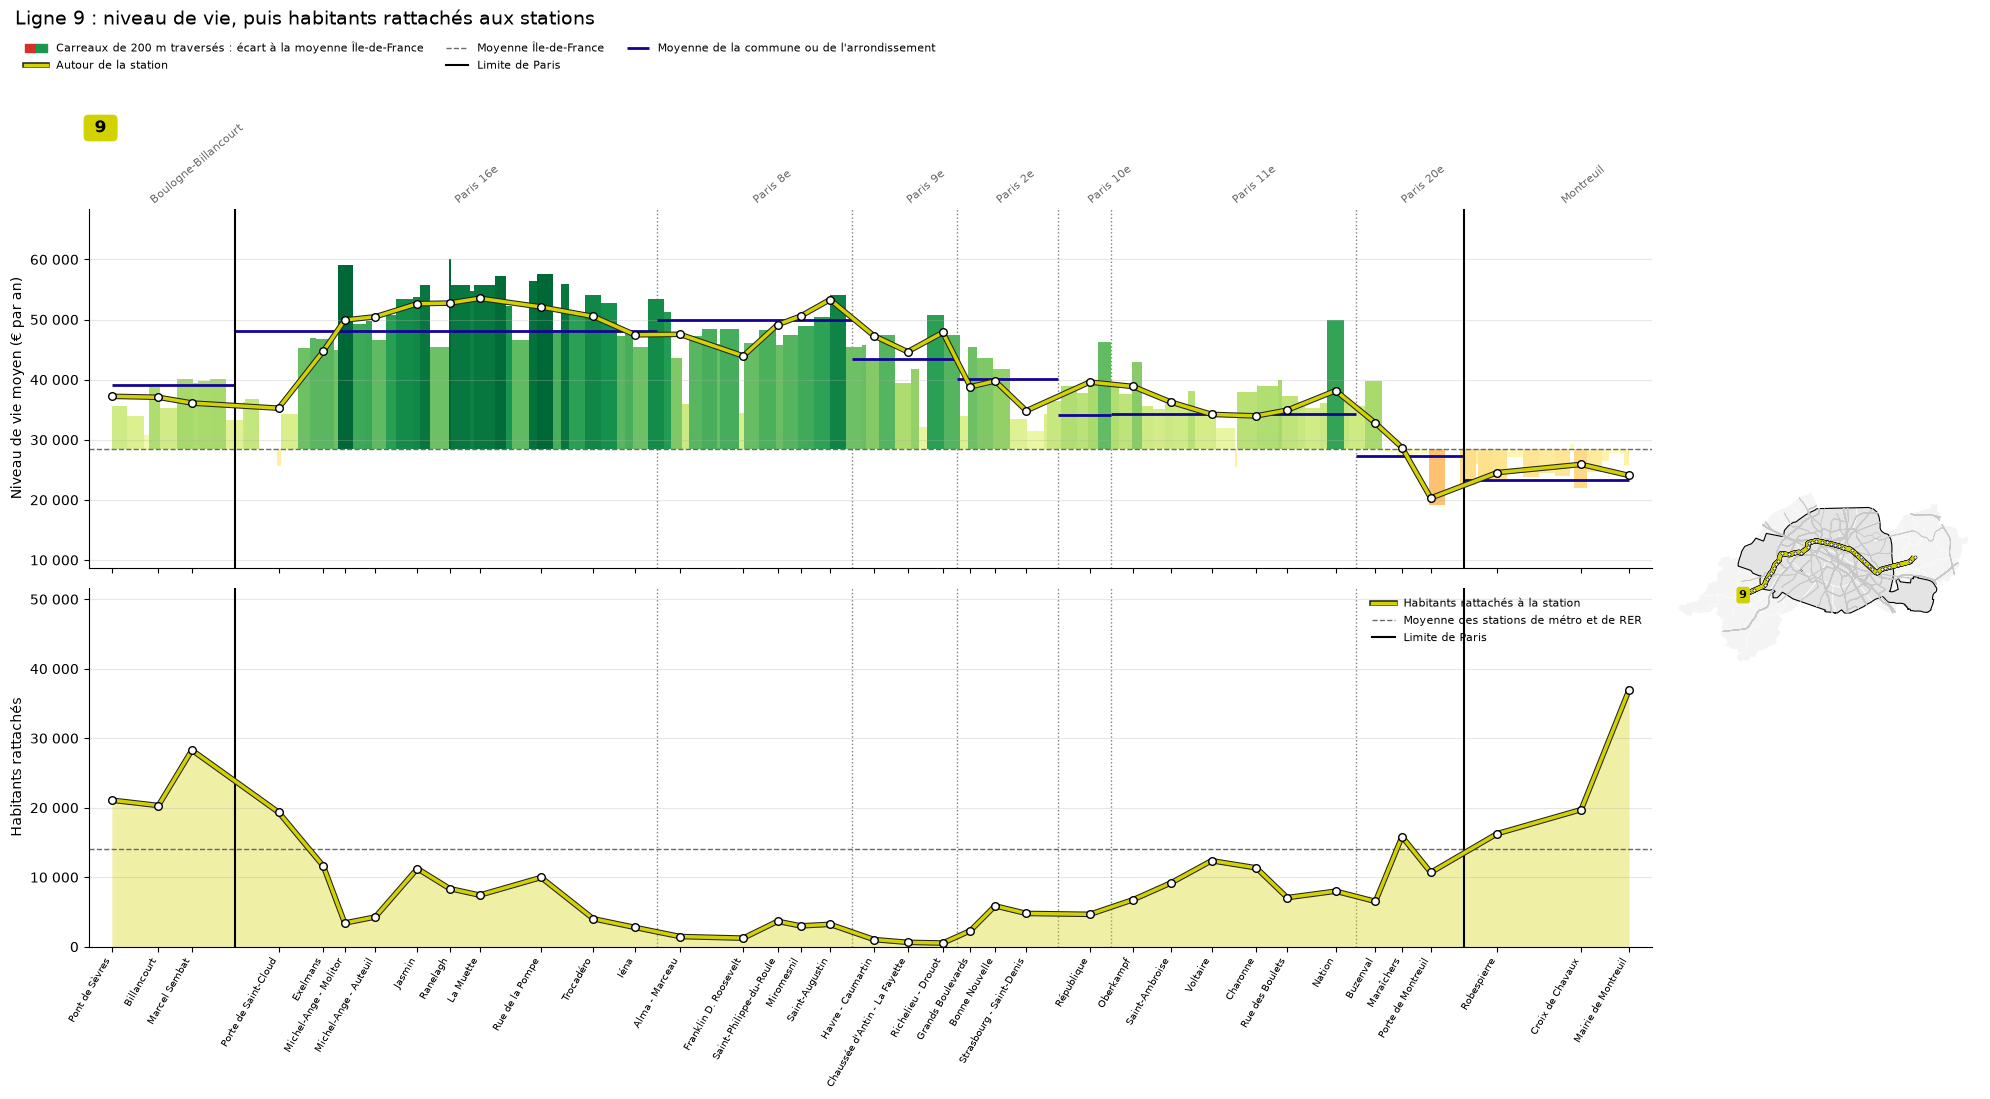

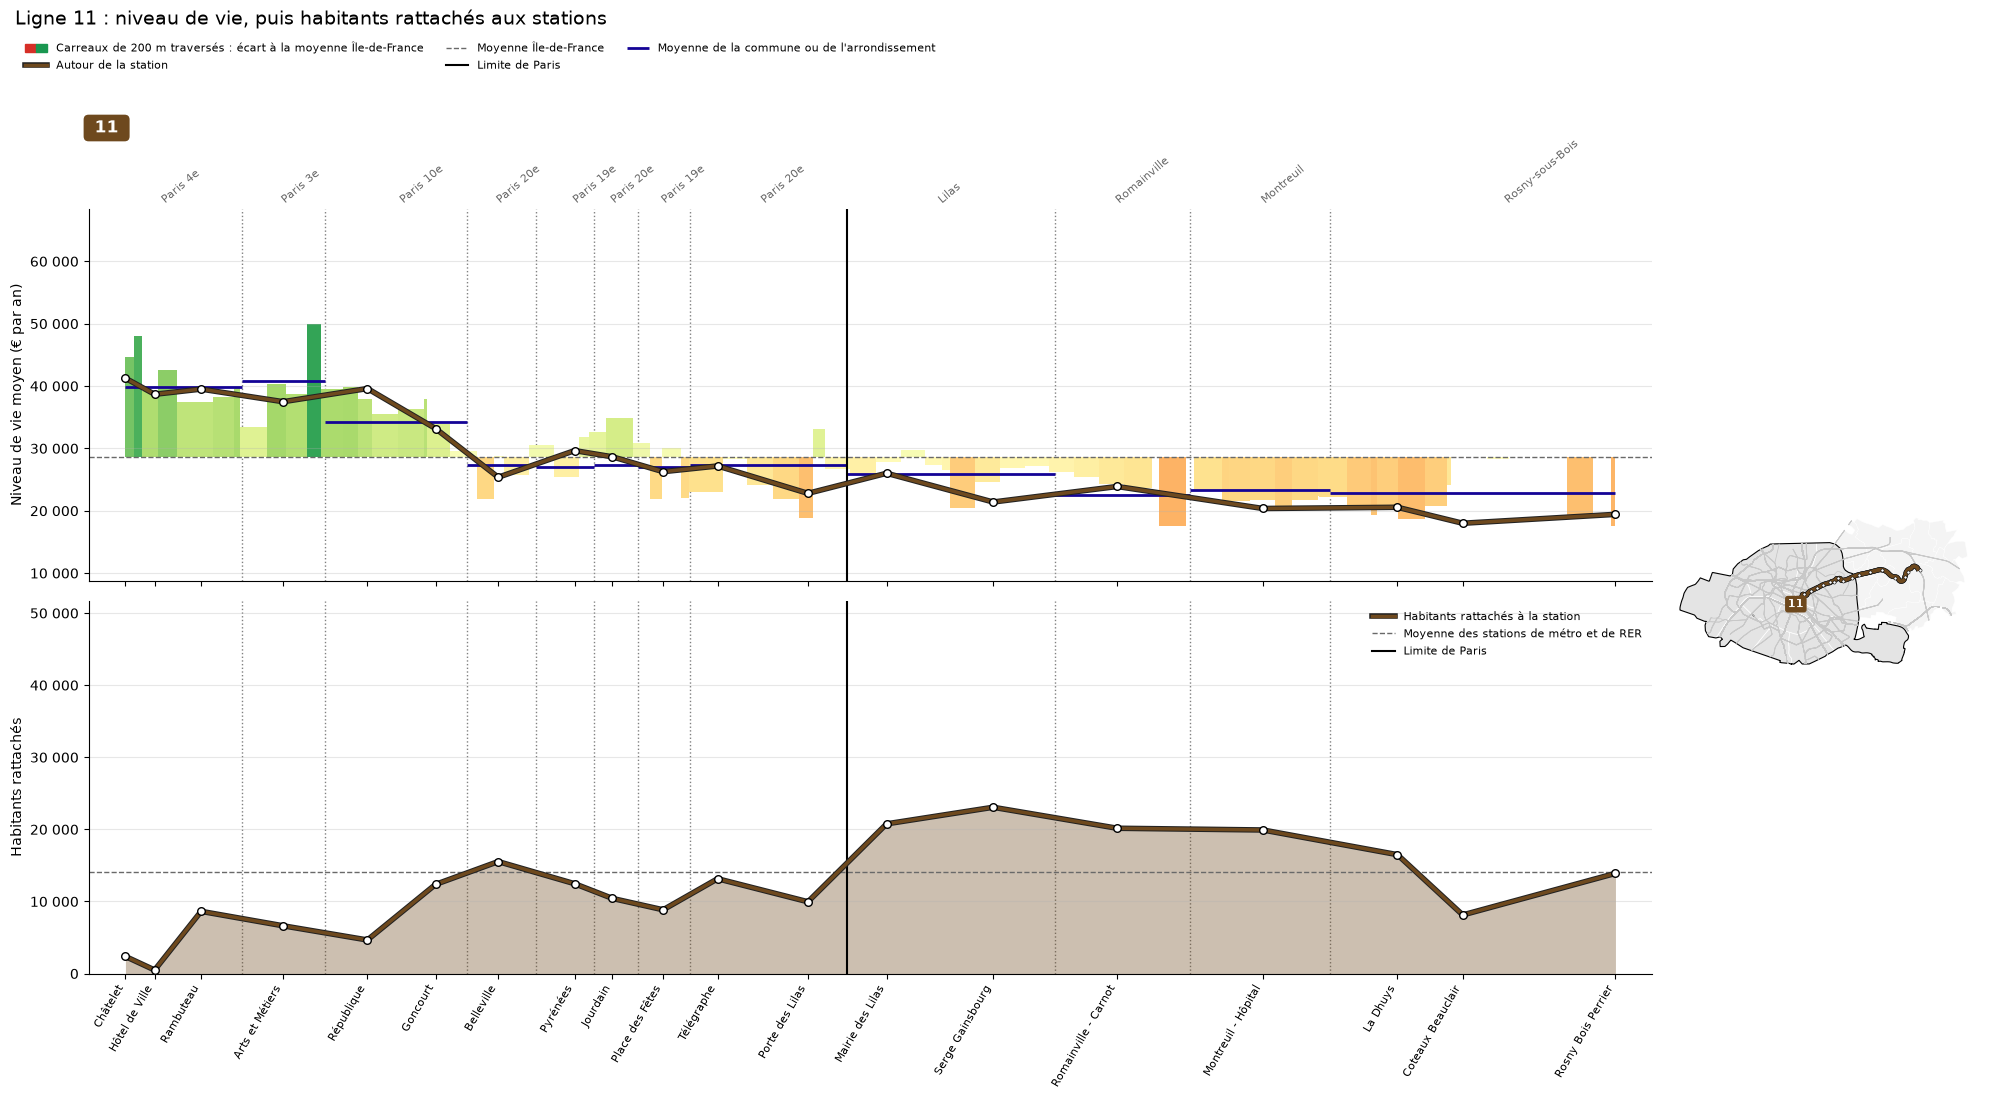

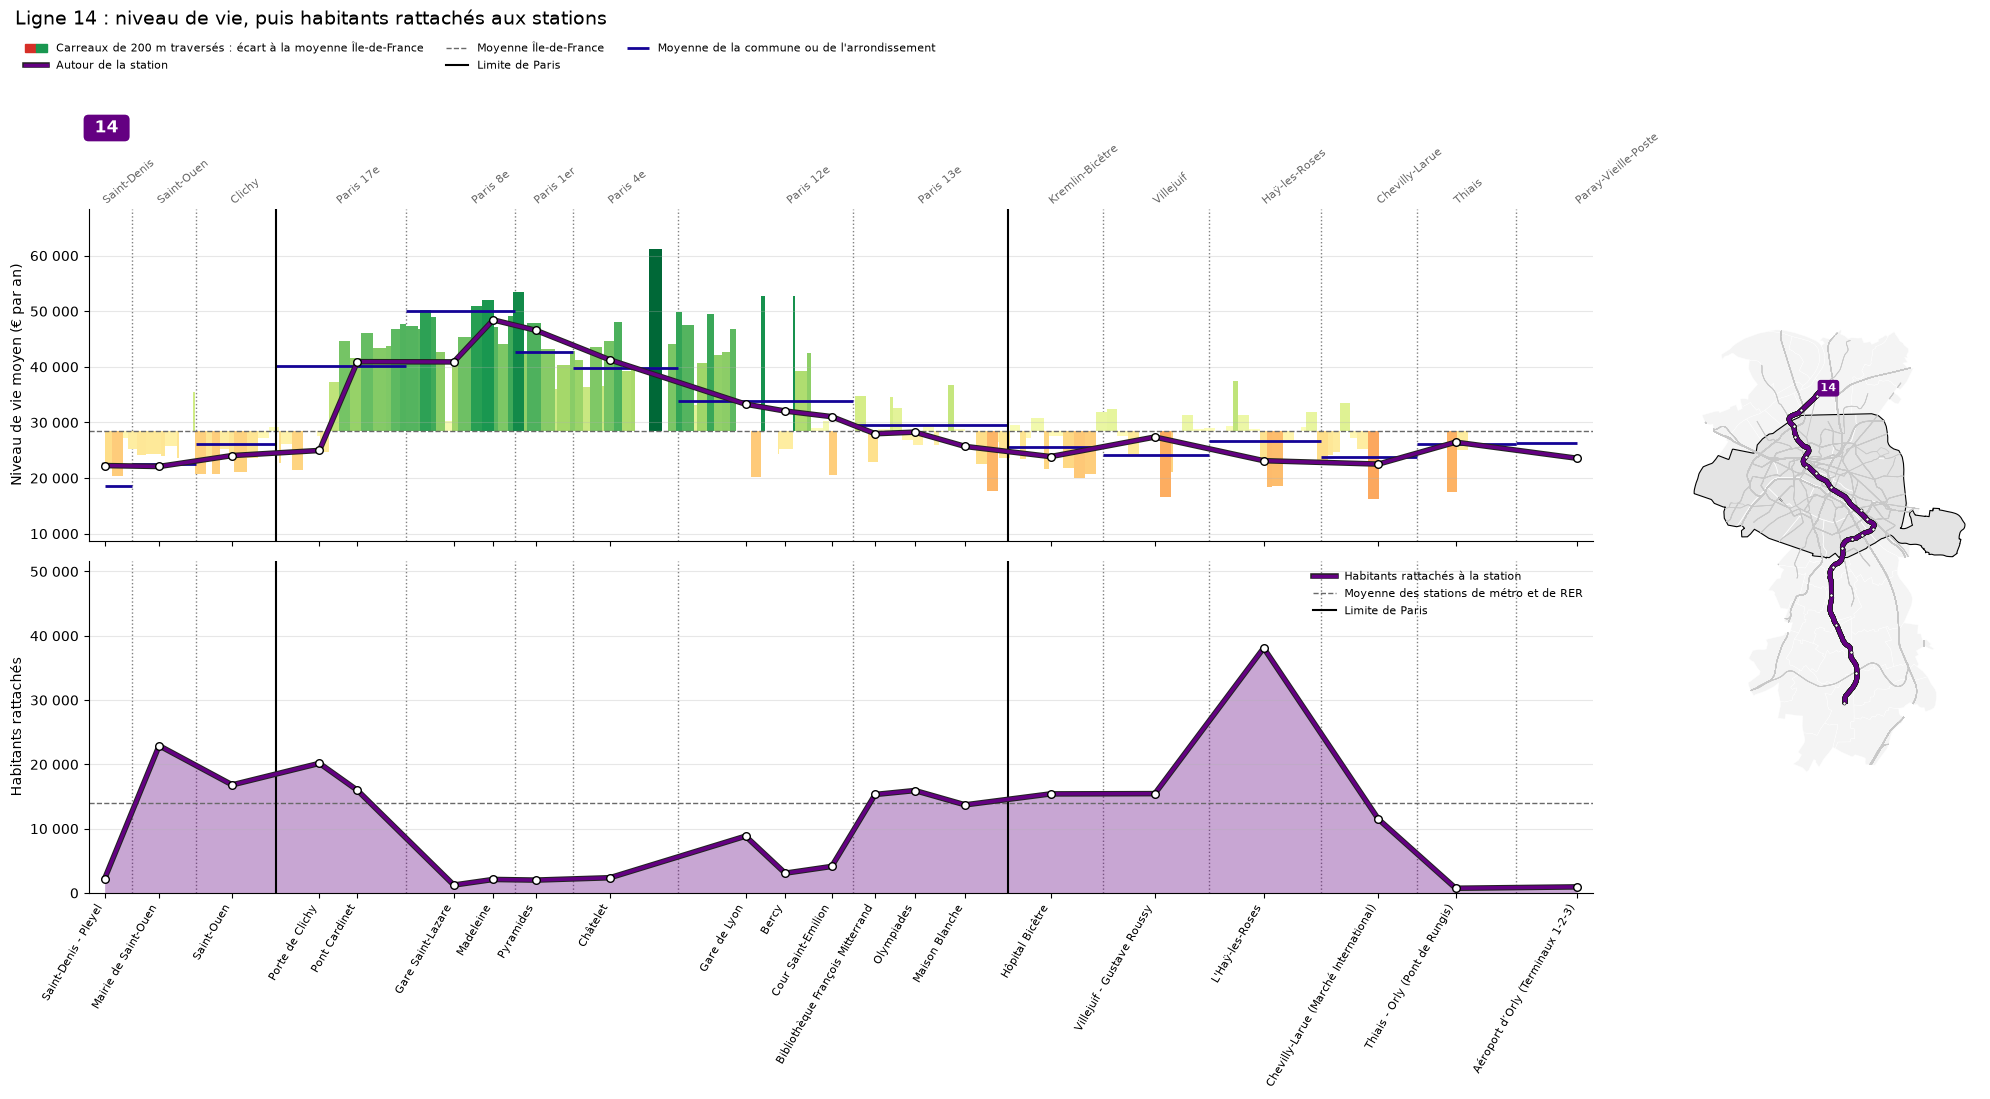

In [12]:
from IPython.display import display

# Figures déjà calculées en II.2 (mêmes échelles que le RER B et les lignes 1 et 13)
display(figures_rer["A"][0].figure)
for nom in ["2", "9", "11", "14"]:
    display(figures_metro[nom][0].figure)

### A.3 Les banlieues plus riches que Paris

En vert, les communes de petite couronne dont le niveau de vie moyen dépasse celui de Paris (plus le vert est foncé, plus elles sont riches) ; les lignes de métro et de RER par-dessus.

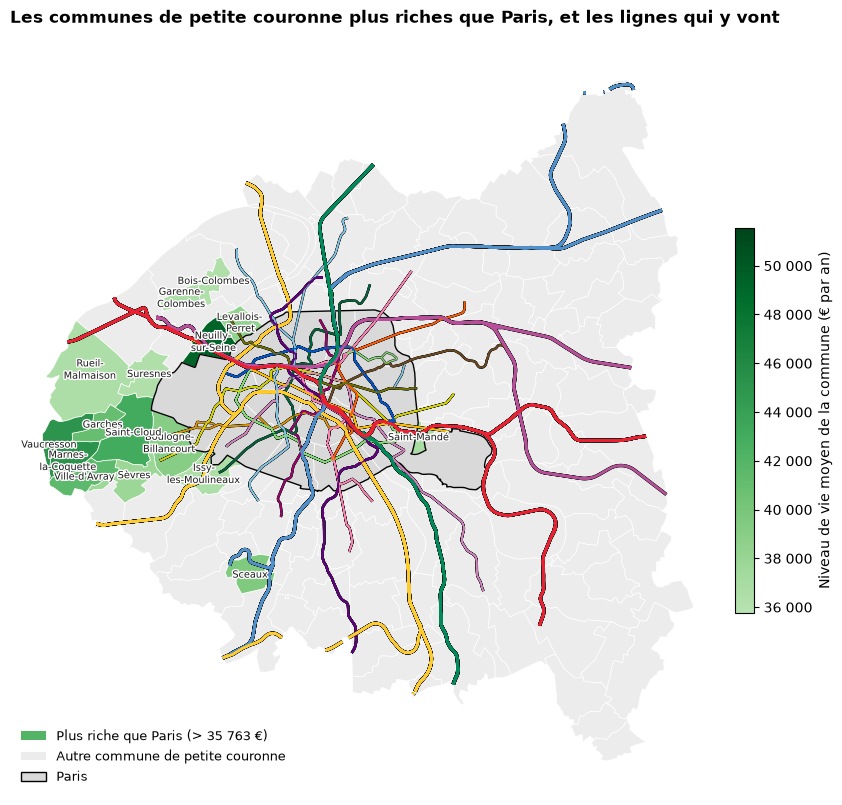

In [13]:
ax = generer_carte_communes_riches(gpd_communes, gpd_zones, nv_paris, gpd_idfm)
enregistrer_graphique(ax, "Communes plus riches que Paris")
plt.show()

> **Lecture :** Neuilly-sur-Seine, la commune la plus riche de la petite couronne, a un niveau de vie moyen de 49 300 € par an, 38 % de plus que Paris (35 800 €). Seize communes dépassent Paris : quinze dans les Hauts-de-Seine, surtout à l'ouest, et Saint-Mandé dans le Val-de-Marne ; aucune en Seine-Saint-Denis.
>
> *Champ : habitants de Paris et de la petite couronne.* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

### A.4 Le relief du niveau de vie à Paris

Chaque point de la surface est le niveau de vie moyen des habitants dans un carré de 1 km de côté centré sur lui (moyenne pondérée par la population, sur la grille de 200 m de Filosofi), lissant le relief sans effacer les quartiers.

- **Couleurs** : les mêmes que les montagnes, rouge sous la moyenne de l'Île-de-France, vert au-dessus.
- **Trous** : pas d'habitants (bois de Boulogne et de Vincennes, grands parcs).

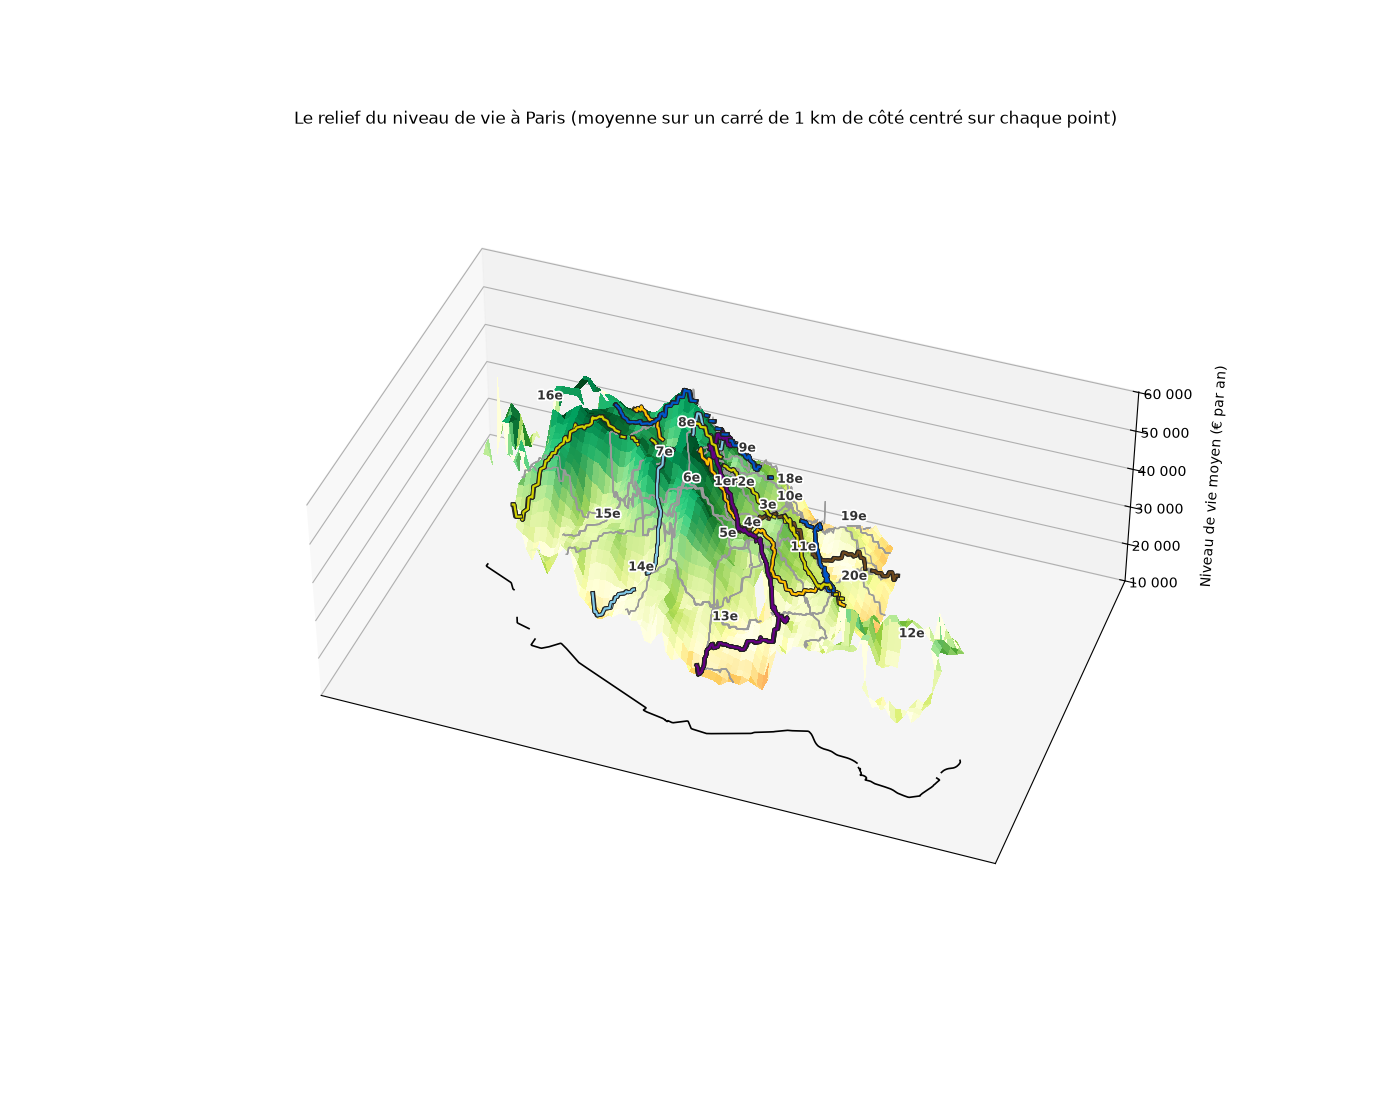

In [14]:
# Figure interactive : clic gauche + glisser pour tourner, clic droit pour zoomer
%matplotlib widget
from IPython.display import display

gpd_paris = gpd_communes[gpd_communes["nom"].str.startswith("Paris")].to_crs(3035)
grille = construire_grille_nv(df_filosofi, gpd_paris.union_all(), rayon=2)

# Lignes mises en valeur au départ : celles des montagnes ; les autres sont en gris
selection = list(lignes_metro)
with plt.ioff():  # on affiche nous-mêmes la figure, sous les boutons
    ax, traits = generer_relief_3d(grille, nv_moyen, gpd_idfm, gpd_paris, selection)
enregistrer_graphique(ax, "Relief 3D du niveau de vie à Paris")
display(ajouter_selecteur_lignes(ax, traits, selection), ax.figure.canvas)

> **Lecture :** le point le plus haut du relief, dans le 16e arrondissement, correspond à un niveau de vie moyen de 59 100 € par an (moyenne sur un carré de 1 km de côté) ; le point le plus bas, dans le 18e, est à 16 400 €, soit 3,6 fois moins.
>
> *Champ : habitants de Paris ; points avec au moins 100 habitants dans le carré de 1 km.* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

Les sommets, là où le niveau de vie est le plus élevé (ouest de Paris : 7e, 8e, 16e, 17e), sont aussi très bien desservis : les lignes 2, 9 et 13 les traversent avant de redescendre vers des quartiers plus modestes. Le principal nœud du réseau, Châtelet, se trouve lui en contrebas de ces sommets.

Attention : ce rendu est lissé sur 1 km et efface les contrastes de revenus très locaux (une cité HLM à côté d'une rue aisée).